In [3]:

import sys
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import joblib
import json
import os

RESULTS_DIR = "/home/claude/model_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

from scipy.stats import randint, uniform, loguniform

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import average_precision_score, roc_auc_score, make_scorer
from sklearn.base import clone

from sklearn.model_selection import RandomizedSearchCV


RANDOM_STATE = 42


df = pd.read_csv("/content/pindis_propensity_train.csv")
df.head(10)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   n_orders             300 non-null    int64  
 1   n_lines              300 non-null    int64  
 2   total_revenue        300 non-null    float64
 3   avg_line_value       300 non-null    float64
 4   n_brands             300 non-null    int64  
 5   n_categories         300 non-null    int64  
 6   total_boxes          300 non-null    int64  
 7   recency_days         300 non-null    int64  
 8   tenure_days          300 non-null    int64  
 9   last_max_line        300 non-null    float64
 10  orders_per_month     300 non-null    float64
 11  target_hist_orders   300 non-null    float64
 12  target_hist_revenue  300 non-null    float64
 13  ever_bought_target   300 non-null    int64  
 14  days_since_target    300 non-null    float64
 15  rid                  300 non-null    int

In [4]:

id_col = "rid"
target_col = "label"





feature_cols = [c for c in df.columns if c not in (id_col, target_col)]

X = df[feature_cols].copy()
y = df[target_col].copy()

print(f"Data shape: {X.shape}, positive rate: {y.mean():.3f}")


Data shape: (300, 15), positive rate: 0.167


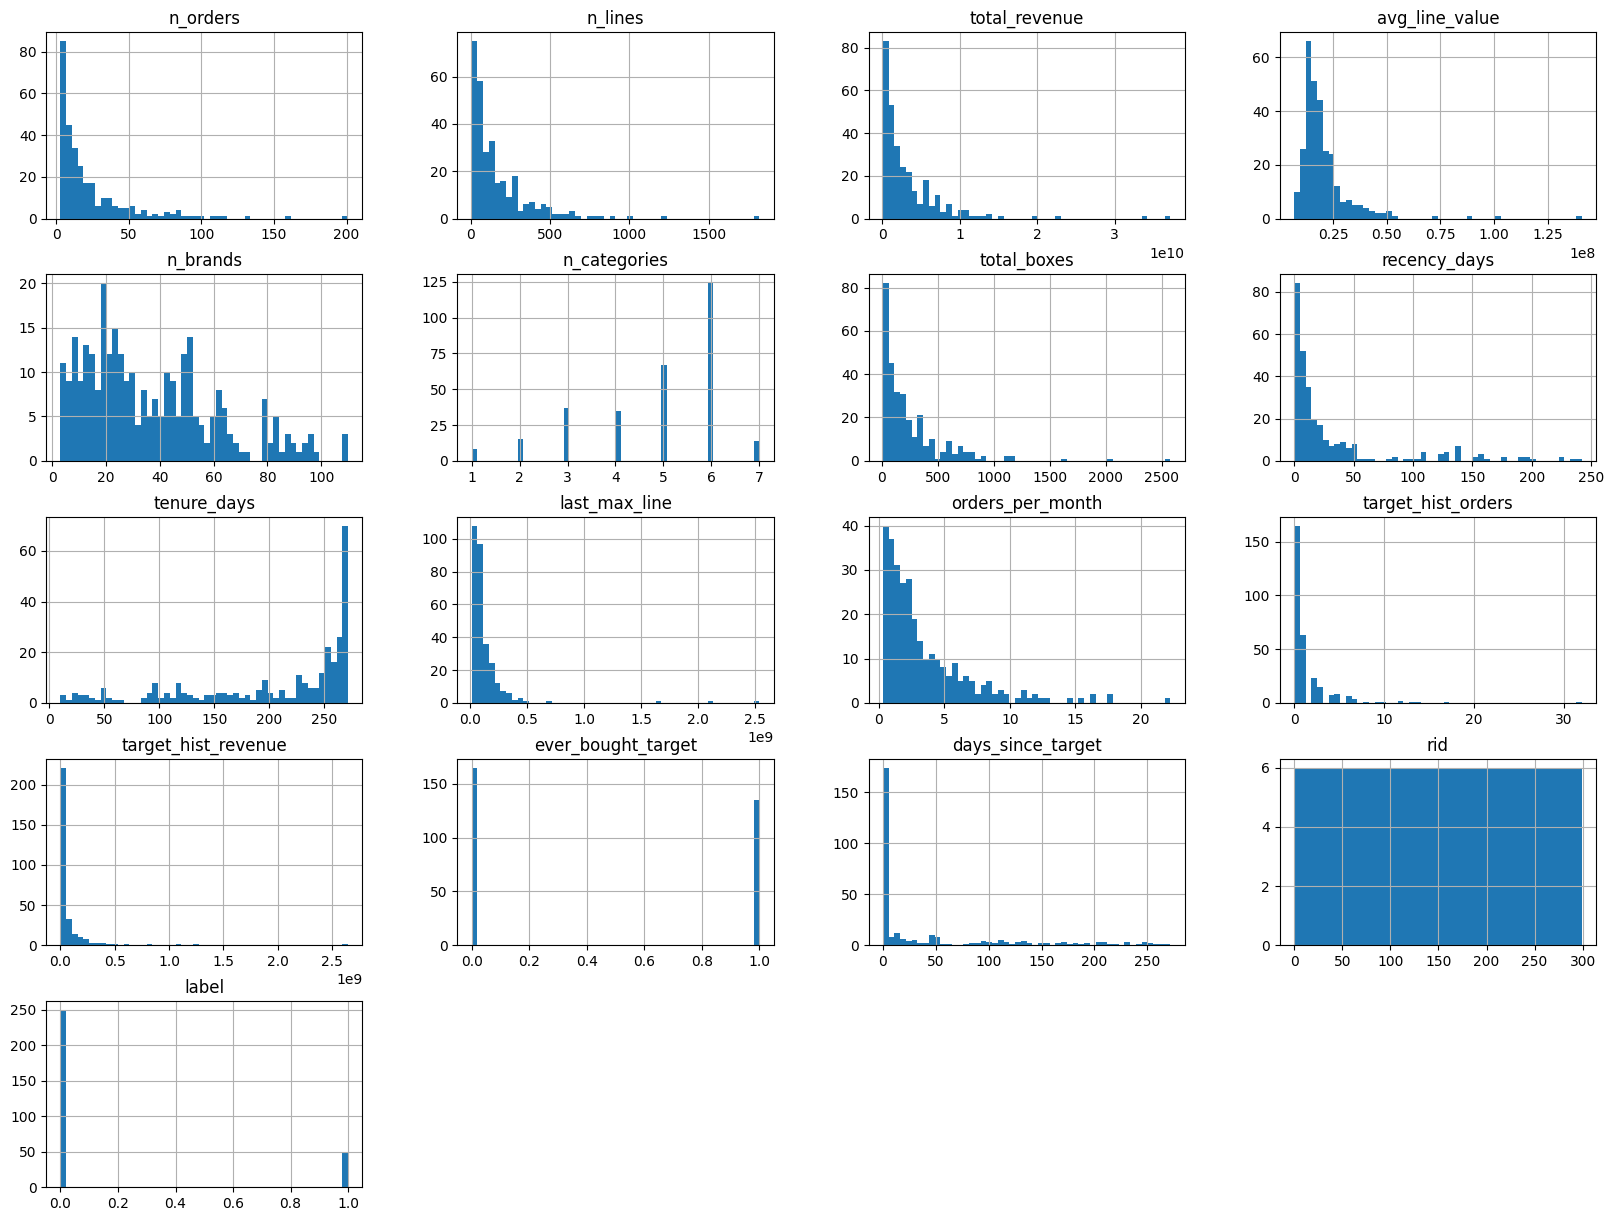

In [5]:
import matplotlib.pyplot as plt
df.hist(bins=50, figsize=(20,15))
plt.show()

In [6]:
from pandas.plotting import scatter_matrix

corr_matrix = df.corr()
corr_matrix["label"].sort_values(ascending=False)



,label
label,1.000000
target_hist_orders,0.334142
n_orders,0.311414
orders_per_month,0.302683
ever_bought_target,0.278669
n_lines,0.222283
target_hist_revenue,0.218293
total_revenue,0.200450
total_boxes,0.195546
n_brands,0.173570


array([[<Axes: xlabel='label', ylabel='label'>,
        <Axes: xlabel='target_hist_orders', ylabel='label'>,
        <Axes: xlabel='n_orders', ylabel='label'>,
        <Axes: xlabel='orders_per_month', ylabel='label'>,
        <Axes: xlabel='ever_bought_target', ylabel='label'>,
        <Axes: xlabel='n_lines', ylabel='label'>],
       [<Axes: xlabel='label', ylabel='target_hist_orders'>,
        <Axes: xlabel='target_hist_orders', ylabel='target_hist_orders'>,
        <Axes: xlabel='n_orders', ylabel='target_hist_orders'>,
        <Axes: xlabel='orders_per_month', ylabel='target_hist_orders'>,
        <Axes: xlabel='ever_bought_target', ylabel='target_hist_orders'>,
        <Axes: xlabel='n_lines', ylabel='target_hist_orders'>],
       [<Axes: xlabel='label', ylabel='n_orders'>,
        <Axes: xlabel='target_hist_orders', ylabel='n_orders'>,
        <Axes: xlabel='n_orders', ylabel='n_orders'>,
        <Axes: xlabel='orders_per_month', ylabel='n_orders'>,
        <Axes: xlabel='ever_b

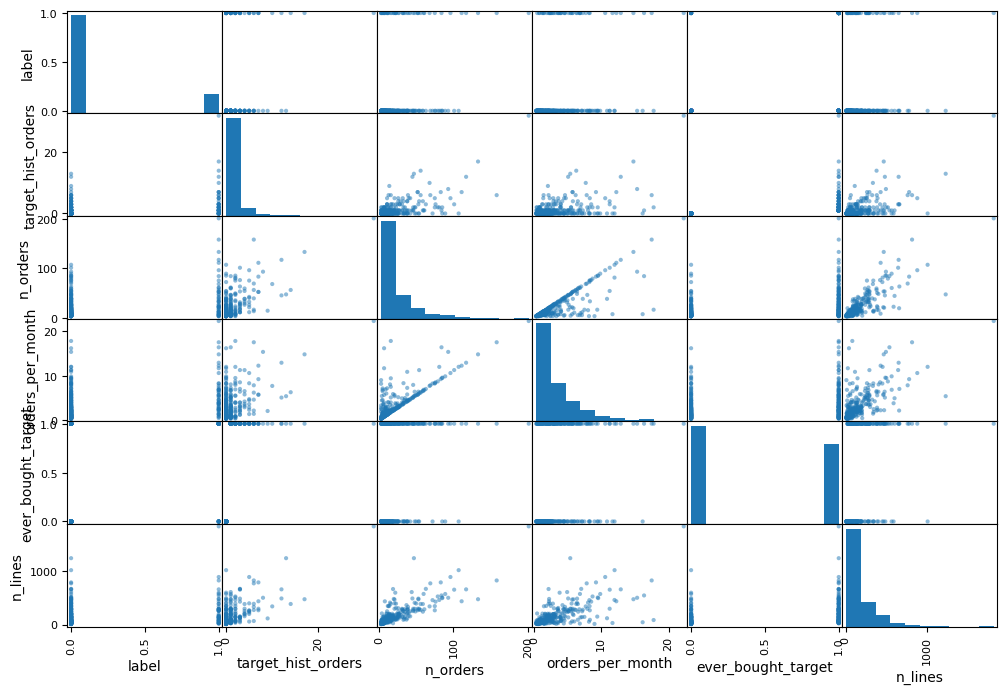

In [7]:

attributes = ["label", "target_hist_orders", "n_orders", "orders_per_month", "ever_bought_target", "n_lines"]
scatter_matrix(df[attributes], figsize=(12, 8))

In [8]:

# 2. Feature prep


NEVER_SENTINEL = 9999
CAP_DAYS_SINCE_TARGET = 400  # anything at/after the sentinel gets capped here

def cap_days_since_target(df_):
    df_ = df_.copy()
    df_["days_since_target"] = df_["days_since_target"].clip(
        upper=CAP_DAYS_SINCE_TARGET
    )
    return df_



skewed_cols = [
    "n_orders", "n_lines", "total_revenue", "avg_line_value",
    "total_boxes", "last_max_line", "target_hist_orders",
    "target_hist_revenue", "recency_days", "tenure_days",
    "days_since_target",
]
skewed_cols = [c for c in skewed_cols if c in feature_cols]

passthrough_cols = [c for c in feature_cols if c not in skewed_cols]

preprocess = ColumnTransformer(
    transformers=[
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
         skewed_cols),
        ("pass", "passthrough", passthrough_cols),
    ]
)

pipe_cap = Pipeline(steps=[
    ("cap", FunctionTransformer(cap_days_since_target, feature_names_out="one-to-one")),
    ("preprocess", preprocess),
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(
        solver="saga",          # supports l1, l2, and elasticnet penalties
        max_iter=5000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    )),
])



In [9]:

# 3. Custom Precision@Top-10% scorer

def precision_at_top_k(y_true, y_score, k_frac=0.10):
    n = len(y_true)
    k = max(1, int(np.ceil(n * k_frac)))
    order = np.argsort(-y_score)
    top_k_idx = order[:k]
    return np.asarray(y_true)[top_k_idx].mean()

precision_at_10_scorer = make_scorer(
    precision_at_top_k, response_method="predict_proba", k_frac=0.10
)

pr_auc_scorer = make_scorer(average_precision_score, response_method="predict_proba")
roc_auc_scorer = make_scorer(roc_auc_score, response_method="predict_proba")


In [10]:

# 4. Hyperparameter search (nested inside CV via GridSearchCV)

param_grid = [
    {  # Ridge (L2)
        "clf__penalty": ["l2"],
        "clf__C": [0.01, 0.02, 0.03, 0.05, 0.1, 0.3, 1],
    },
    {  # Elastic Net
        "clf__penalty": ["elasticnet"],
        "clf__C": [0.01, 0.02, 0.03, 0.05, 0.1, 0.3, 1],
        "clf__l1_ratio": [0.2, 0.3, 0.4, 0.7, 0.9],
    },
]

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)

grid = GridSearchCV(
    estimator=pipe_cap,
    param_grid=param_grid,
    scoring=pr_auc_scorer,   # optimize for the competition's primary metric
    cv=cv,
    n_jobs=-1,
    refit=True,
)

grid.fit(X, y)

print("\nBest params:", grid.best_params_)
print(f"Best CV PR-AUC: {grid.best_score_:.4f}")



Best params: {'clf__C': 0.01, 'clf__l1_ratio': 0.2, 'clf__penalty': 'elasticnet'}
Best CV PR-AUC: 0.4521


In [11]:

# 5. Report all three metrics for the best model via the same CV scheme

from sklearn.model_selection import cross_val_score

best_pipe = grid.best_estimator_

pr_scores = cross_val_score(best_pipe, X, y, cv=cv, scoring=pr_auc_scorer, n_jobs=-1)
roc_scores = cross_val_score(best_pipe, X, y, cv=cv, scoring=roc_auc_scorer, n_jobs=-1)
p10_scores = cross_val_score(best_pipe, X, y, cv=cv, scoring=precision_at_10_scorer, n_jobs=-1)

print(f"\nCV PR-AUC        : {pr_scores.mean():.4f} +/- {pr_scores.std():.4f}")
print(f"CV ROC-AUC        : {roc_scores.mean():.4f} +/- {roc_scores.std():.4f}")
print(f"CV Precision@Top10%: {p10_scores.mean():.4f} +/- {p10_scores.std():.4f}")



CV PR-AUC        : 0.4521 +/- 0.0975
CV ROC-AUC        : 0.7782 +/- 0.0512
CV Precision@Top10%: 0.3933 +/- 0.1692


In [12]:

# 6. Fit final model on ALL training data

final_model = grid.best_estimator_

# Feature names after log-transform + passthrough (order = skewed_cols + passthrough_cols)
final_feature_names = skewed_cols + passthrough_cols
coefs = final_model.named_steps["clf"].coef_[0]

coef_df = pd.DataFrame({
    "feature": final_feature_names,
    "coefficient": coefs,
}).sort_values("coefficient", key=np.abs, ascending=False)

print("\nCoefficients (sorted by |value|):")
print(coef_df.to_string(index=False))



Coefficients (sorted by |value|):
            feature  coefficient
 target_hist_orders     0.167161
       recency_days    -0.135061
   orders_per_month     0.115704
target_hist_revenue     0.099591
 ever_bought_target     0.084773
           n_orders     0.038468
            n_lines     0.000000
      last_max_line     0.000000
        total_boxes     0.000000
     avg_line_value     0.000000
      total_revenue     0.000000
  days_since_target     0.000000
        tenure_days     0.000000
       n_categories     0.000000
           n_brands     0.000000


In [13]:

# 2. Shared CV scheme + metrics (identical to the linear model script,

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)

def precision_at_top_k(y_true, y_score, k_frac=0.10):
    n = len(y_true)
    k = max(1, int(np.ceil(n * k_frac)))
    order = np.argsort(-y_score)
    top_k_idx = order[:k]
    return np.asarray(y_true)[top_k_idx].mean()

pr_auc_scorer = make_scorer(average_precision_score, response_method="predict_proba")
roc_auc_scorer = make_scorer(roc_auc_score, response_method="predict_proba")
precision_at_10_scorer = make_scorer(
    precision_at_top_k, response_method="predict_proba", k_frac=0.10
)
scoring = {"pr_auc": pr_auc_scorer, "roc_auc": roc_auc_scorer, "p_at_10": precision_at_10_scorer}


In [14]:

# 3. Model 1 — Logistic Regression (L2 / ElasticNet), with the same
#    preprocessing as train_linear_model.py

CAP_DAYS_SINCE_TARGET = 400

def cap_days_since_target(df_):
    df_ = df_.copy()
    df_["days_since_target"] = df_["days_since_target"].clip(upper=CAP_DAYS_SINCE_TARGET)
    return df_

skewed_cols = [
    "n_orders", "n_lines", "total_revenue", "avg_line_value",
    "total_boxes", "last_max_line", "target_hist_orders",
    "target_hist_revenue", "recency_days", "tenure_days",
    "days_since_target",
]
skewed_cols = [c for c in skewed_cols if c in feature_cols]
passthrough_cols = [c for c in feature_cols if c not in skewed_cols]

preprocess = ColumnTransformer(
    transformers=[
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), skewed_cols),
        ("pass", "passthrough", passthrough_cols),
    ]
)

logreg_pipe = Pipeline(steps=[
    ("cap", FunctionTransformer(cap_days_since_target, feature_names_out="one-to-one")),
    ("preprocess", preprocess),
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(
        solver="saga", max_iter=5000, class_weight="balanced", random_state=RANDOM_STATE,
    )),
])

logreg_param_grid = [
    {"clf__penalty": ["l2"], "clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    {"clf__penalty": ["elasticnet"], "clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
     "clf__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]},
]


In [15]:

# 4. Model 2 — Random Forest

rf_pipe = Pipeline(steps=[
    ("clf", RandomForestClassifier(
        n_estimators=400, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1,
    )),
])

rf_param_grid = {
    "clf__max_depth": [3, 4, 5],
    "clf__min_samples_leaf": [3,4,5, ],
    "clf__max_features": ["sqrt", 0.5],
}


In [16]:

# 5. Model 3 — Gradient Boosting

gbc_pipe = Pipeline(steps=[
    ("clf", GradientBoostingClassifier(random_state=RANDOM_STATE)),
])

gbc_param_grid = {
    "clf__n_estimators": [150],
    "clf__max_depth": [2, 3],
    "clf__learning_rate": [0.05, 0.1],
    "clf__subsample": [0.8, 1.0],
    "clf__min_samples_leaf": [10],
}


In [17]:

# 6. Run ONE model per invocation

models = {
    "logreg": ("Logistic Regression", logreg_pipe, logreg_param_grid),
    "rf": ("Random Forest", rf_pipe, rf_param_grid),
    "gbc": ("Gradient Boosting", gbc_pipe, gbc_param_grid),
}

def run_one_model(key):
    name, pipe, grid_params = models[key]
    print(f"Tuning {name}...")
    grid = GridSearchCV(
        estimator=pipe,
        param_grid=grid_params,
        scoring=pr_auc_scorer,   # select hyperparams by PR-AUC
        cv=cv,
        n_jobs=-1,
        refit=True,
    )
    grid.fit(X, y)
    best_pipe = grid.best_estimator_

    pr = cross_val_score(best_pipe, X, y, cv=cv, scoring=pr_auc_scorer, n_jobs=-1)
    roc = cross_val_score(best_pipe, X, y, cv=cv, scoring=roc_auc_scorer, n_jobs=-1)
    p10 = cross_val_score(best_pipe, X, y, cv=cv, scoring=precision_at_10_scorer, n_jobs=-1)

    metrics = {
        "model": name,
        "best_params": {k: str(v) for k, v in grid.best_params_.items()},
        "pr_auc_mean": float(pr.mean()), "pr_auc_std": float(pr.std()),
        "roc_auc_mean": float(roc.mean()), "roc_auc_std": float(roc.std()),
        "p_at_10_mean": float(p10.mean()), "p_at_10_std": float(p10.std()),
    }

    joblib.dump(best_pipe, f"{RESULTS_DIR}/{key}_pipe.joblib")
    with open(f"{RESULTS_DIR}/{key}_metrics.json", "w") as f:
        json.dump(metrics, f, indent=2)

    print(f"  Best params: {grid.best_params_}")
    print(f"  PR-AUC: {pr.mean():.4f} +/- {pr.std():.4f}")
    print(f"  ROC-AUC: {roc.mean():.4f} +/- {roc.std():.4f}")
    print(f"  P@Top10%: {p10.mean():.4f} +/- {p10.std():.4f}")
    print(f"Saved {key} pipeline + metrics to {RESULTS_DIR}/")

def run_summary():
    results = []
    fitted = {}
    for key, (name, _, _) in models.items():
        metrics_path = f"{RESULTS_DIR}/{key}_metrics.json"
        pipe_path = f"{RESULTS_DIR}/{key}_pipe.joblib"
        if not (os.path.exists(metrics_path) and os.path.exists(pipe_path)):
            print(f"WARNING: missing results for {name} ({key}) — run it first. Skipping.")
            continue
        with open(metrics_path) as f:
            results.append(json.load(f))
        fitted[name] = joblib.load(pipe_path)

    if not results:
        print("No model results found. Run logreg/rf/gbc first.")
        return

    results_df = pd.DataFrame(results).sort_values("pr_auc_mean", ascending=False)

    print("=" * 80)
    print("MODEL COMPARISON (ranked by PR-AUC, the project's primary metric)")
    print("=" * 80)
    for _, row in results_df.iterrows():
        print(f"{row['model']:22s} | PR-AUC: {row['pr_auc_mean']:.4f} +/- {row['pr_auc_std']:.4f} "
              f"| ROC-AUC: {row['roc_auc_mean']:.4f} +/- {row['roc_auc_std']:.4f} "
              f"| P@Top10%: {row['p_at_10_mean']:.4f} +/- {row['p_at_10_std']:.4f}")

    winner_name = results_df.iloc[0]["model"]
    print(f"\nBest model by PR-AUC: {winner_name}")

    winner_pipe = fitted[winner_name]
    out_path = "/mnt/user-data/outputs/propensity_best_model.joblib"
    joblib.dump(winner_pipe, out_path)
    print(f"Saved best model ({winner_name}) to {out_path}")

    results_df.to_csv("/mnt/user-data/outputs/model_comparison_results.csv", index=False)
    print("Saved comparison table to /mnt/user-data/outputs/model_comparison_results.csv")

run_one_model("logreg")
run_one_model("rf")
run_one_model("gbc")


Tuning Logistic Regression...
  Best params: {'clf__C': 0.03, 'clf__l1_ratio': 0.5, 'clf__penalty': 'elasticnet'}
  PR-AUC: 0.4476 +/- 0.1047
  ROC-AUC: 0.7790 +/- 0.0545
  P@Top10%: 0.3933 +/- 0.1692
Saved logreg pipeline + metrics to /home/claude/model_results/
Tuning Random Forest...
  Best params: {'clf__max_depth': 3, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 4}
  PR-AUC: 0.4498 +/- 0.1005
  ROC-AUC: 0.7778 +/- 0.0617
  P@Top10%: 0.4000 +/- 0.1700
Saved rf pipeline + metrics to /home/claude/model_results/
Tuning Gradient Boosting...
  Best params: {'clf__learning_rate': 0.05, 'clf__max_depth': 2, 'clf__min_samples_leaf': 10, 'clf__n_estimators': 150, 'clf__subsample': 1.0}
  PR-AUC: 0.4359 +/- 0.0855
  ROC-AUC: 0.7670 +/- 0.0616
  P@Top10%: 0.4267 +/- 0.1420
Saved gbc pipeline + metrics to /home/claude/model_results/


In [18]:
# Random Forest — widened search space

rf_pipe = Pipeline(steps=[
    ("clf", RandomForestClassifier(
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1,
        oob_score=True, bootstrap=True,
    )),
])

rf_param_dist = {
    "clf__n_estimators": randint(200, 800),
    "clf__max_depth": [2, 3, 4, 5, 6, 8, None],          # None = unlimited
    "clf__min_samples_leaf": randint(2, 30),
    "clf__min_samples_split": randint(2, 40),
    "clf__max_features": ["sqrt", "log2", 0.3, 0.5, 0.7, None],
    "clf__max_samples": uniform(0.5, 0.5),
    "clf__criterion": ["gini", "entropy"],
}


In [19]:

# Gradient Boosting — widened search space + early-stopping-style control

gbc_pipe = Pipeline(steps=[
    ("clf", GradientBoostingClassifier(
        random_state=RANDOM_STATE,
        validation_fraction=0.15,
        n_iter_no_change=15,   # stop early if no improvement -> lets n_estimators run high safely
        tol=1e-4,
    )),
])


gbc_param_dist = {
    "clf__n_estimators": randint(400, 800),
    "clf__max_depth": [2, 3, 4],
    "clf__learning_rate": loguniform(0.03, 0.08),
    "clf__subsample": uniform(0.4, 0.3),
    "clf__min_samples_leaf": randint(15, 35),
    "clf__min_samples_split": randint(20, 45),
    "clf__max_features": [None, 0.7, 0.9],
}

models = {
    "rf": ("Random Forest", rf_pipe, rf_param_dist),
    "gbc": ("Gradient Boosting", gbc_pipe, gbc_param_dist),
}

N_ITER = 150

def run_one_model(key):
    name, pipe, param_dist = models[key]
    print(f"Randomized search for {name} ({N_ITER} candidates)...")

    search = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=param_dist,
        n_iter=N_ITER,
        scoring=pr_auc_scorer,
        cv=cv,
        n_jobs=-1,
        random_state=RANDOM_STATE,
        refit=True,
    )
    search.fit(X, y)
    best_pipe = search.best_estimator_

    pr = cross_val_score(best_pipe, X, y, cv=cv, scoring=pr_auc_scorer, n_jobs=-1)
    roc = cross_val_score(best_pipe, X, y, cv=cv, scoring=roc_auc_scorer, n_jobs=-1)
    p10 = cross_val_score(best_pipe, X, y, cv=cv, scoring=precision_at_10_scorer, n_jobs=-1)

    # Report spread across the top-10 candidates too, as a sanity check
    # against overfitting the search to this particular CV split.
    results_df = pd.DataFrame(search.cv_results_)
    top10 = results_df.nlargest(10, "mean_test_score")["mean_test_score"]
    print(f"  Top-10 candidate PR-AUC range: {top10.min():.4f} - {top10.max():.4f} "
          f"(spread: {top10.max() - top10.min():.4f})")
    if top10.max() - top10.min() < 0.02:
        print("  -> Scores are tightly clustered: you're likely near the ceiling "
              "for this model/feature set; further search will mostly chase noise.")

    metrics = {
        "model": name,
        "best_params": {k: str(v) for k, v in search.best_params_.items()},
        "pr_auc_mean": float(pr.mean()), "pr_auc_std": float(pr.std()),
        "roc_auc_mean": float(roc.mean()), "roc_auc_std": float(roc.std()),
        "p_at_10_mean": float(p10.mean()), "p_at_10_std": float(p10.std()),
    }
    joblib.dump(best_pipe, f"{RESULTS_DIR}/{key}_deep_pipe.joblib")
    with open(f"{RESULTS_DIR}/{key}_deep_metrics.json", "w") as f:
        json.dump(metrics, f, indent=2)

    print(f"  Best params: {search.best_params_}")
    print(f"  PR-AUC: {pr.mean():.4f} +/- {pr.std():.4f}")
    print(f"  ROC-AUC: {roc.mean():.4f} +/- {roc.std():.4f}")
    print(f"  P@Top10%: {p10.mean():.4f} +/- {p10.std():.4f}")

def run_summary():
    for key, (name, _, _) in models.items():
        path = f"{RESULTS_DIR}/{key}_deep_metrics.json"
        if os.path.exists(path):
            with open(path) as f:
                m = json.load(f)
            print(f"{name}: PR-AUC {m['pr_auc_mean']:.4f} +/- {m['pr_auc_std']:.4f} | "
                  f"ROC-AUC {m['roc_auc_mean']:.4f} | P@Top10% {m['p_at_10_mean']:.4f}")
        else:
            print(f"{name}: no results yet — run `python tune_trees_deep.py {key}` first")


In [20]:
#run_one_model("logreg")
#run_one_model("rf")
run_one_model("gbc")
run_summary()

Randomized search for Gradient Boosting (150 candidates)...
  Top-10 candidate PR-AUC range: 0.4549 - 0.4704 (spread: 0.0155)
  -> Scores are tightly clustered: you're likely near the ceiling for this model/feature set; further search will mostly chase noise.
  Best params: {'clf__learning_rate': np.float64(0.06092257701789824), 'clf__max_depth': 3, 'clf__max_features': 0.9, 'clf__min_samples_leaf': 33, 'clf__min_samples_split': 38, 'clf__n_estimators': 691, 'clf__subsample': np.float64(0.6148537224198857)}
  PR-AUC: 0.4704 +/- 0.1063
  ROC-AUC: 0.7821 +/- 0.0627
  P@Top10%: 0.4600 +/- 0.1718
Random Forest: no results yet — run `python tune_trees_deep.py rf` first
Gradient Boosting: PR-AUC 0.4704 +/- 0.1063 | ROC-AUC 0.7821 | P@Top10% 0.4600


In [21]:

# 1. Rebuild the three tuned models with the hyperparameters found so far

CAP_DAYS_SINCE_TARGET = 400

def cap_days_since_target(df_):
    df_ = df_.copy()
    df_["days_since_target"] = df_["days_since_target"].clip(upper=CAP_DAYS_SINCE_TARGET)
    return df_


skewed_cols = [
    "n_orders", "n_lines", "total_revenue", "avg_line_value",
    "total_boxes", "last_max_line", "target_hist_orders",
    "target_hist_revenue", "recency_days", "orders_per_month",
    "days_since_target",
]
skewed_cols = [c for c in skewed_cols if c in feature_cols]
passthrough_cols = [c for c in feature_cols if c not in skewed_cols]

preprocess = ColumnTransformer(transformers=[
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), skewed_cols),
    ("pass", "passthrough", passthrough_cols),
])

logreg_pipe = Pipeline(steps=[
    ("cap", FunctionTransformer(cap_days_since_target, feature_names_out="one-to-one")),
    ("preprocess", preprocess),
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(
        solver="saga", max_iter=5000, class_weight="balanced", random_state=RANDOM_STATE,
        penalty="elasticnet", C=0.03, l1_ratio=0.5,
    )),
])

rf_pipe = Pipeline(steps=[
    ("clf", RandomForestClassifier(
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1,
        criterion="entropy", max_depth=8, max_features=0.7,
        max_samples=0.6397801708983792, min_samples_leaf=7,
        min_samples_split=36, n_estimators=236,
    )),
])

gbc_pipe = Pipeline(steps=[
    ("clf", GradientBoostingClassifier(
        random_state=RANDOM_STATE,
        validation_fraction=0.15, n_iter_no_change=15, tol=1e-4,
        learning_rate=0.06092257701789824, max_depth=3, max_features=0.9,
        min_samples_leaf=33, min_samples_split=38, n_estimators=691,
        subsample=0.6148537224198857,
    )),
])

base_models = {"LogReg": logreg_pipe, "RF": rf_pipe, "GBC": gbc_pipe}


In [23]:

# FINAL: Refit tuned GBC on ALL training data, predict on eval set,
# and save submission.csv

EVAL_PATH = "pindis_propensity_eval_features.csv"
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score

#binary_prediction's cutoff:
#   "f1_optimal"
#   "prevalence_match"

THRESHOLD_STRATEGY = "prevalence_match"

# ---- 1. Get out-of-fold probabilities
cv_oof = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof_proba = cross_val_predict(
    gbc_pipe, X, y, cv=cv_oof, method="predict_proba", n_jobs=-1
)[:, 1]

if THRESHOLD_STRATEGY == "f1_optimal":
    thresholds = np.linspace(0.05, 0.95, 181)
    f1_scores = [f1_score(y, (oof_proba >= t).astype(int)) for t in thresholds]
    best_threshold = thresholds[int(np.argmax(f1_scores))]
    print(f"F1-optimal threshold: {best_threshold:.3f} (F1={max(f1_scores):.4f})")

elif THRESHOLD_STRATEGY == "prevalence_match":
    train_prevalence = y.mean()
    best_threshold = np.quantile(oof_proba, 1 - train_prevalence)
    implied_f1 = f1_score(y, (oof_proba >= best_threshold).astype(int))
    print(f"Prevalence-matching threshold: {best_threshold:.3f} "
          f"(targets ~{train_prevalence:.1%} positive rate, F1={implied_f1:.4f})")

else:
    raise ValueError("THRESHOLD_STRATEGY must be 'f1_optimal' or 'prevalence_match'")

# ---- 2. Refit the tuned GBC on ALL training rows (final model) ----
final_gbc = gbc_pipe
final_gbc.fit(X, y)

# ---- 3. Load eval set and predict ----
df_eval = pd.read_csv(EVAL_PATH)

missing_cols = [c for c in feature_cols if c not in df_eval.columns]
assert not missing_cols, f"Eval file is missing expected columns: {missing_cols}"

X_eval = df_eval[feature_cols].copy()
eval_proba = final_gbc.predict_proba(X_eval)[:, 1]
eval_binary = (eval_proba >= best_threshold).astype(int)

# ---- 4. Build submission in the required format ----
submission = pd.DataFrame({
    "rid": df_eval["rid"],
    "p": eval_proba,
    "binary_prediction": eval_binary,
})

# Sanity checks
assert submission["rid"].duplicated().sum() == 0, "Duplicate rid found!"
assert submission.shape[0] == df_eval.shape[0], "Row count mismatch vs eval file!"
assert submission["p"].between(0, 1).all(), "Probabilities out of [0,1] range!"

print(f"\nSubmission shape: {submission.shape}")
print(f"Predicted positive rate: {submission['binary_prediction'].mean():.3f} "
      f"(training positive rate was {y.mean():.3f})")
print(submission.head())

submission.to_csv("submission.csv", index=False)
print("\nSaved submission.csv")

Prevalence-matching threshold: 0.337 (targets ~16.7% positive rate, F1=0.4000)

Submission shape: (100, 3)
Predicted positive rate: 0.190 (training positive rate was 0.167)
   rid         p  binary_prediction
0   26  0.101957                  0
1   41  0.035328                  0
2   91  0.567337                  1
3   70  0.370420                  1
4    6  0.436152                  1

Saved submission.csv


In [24]:

from scipy.stats import loguniform
from sklearn.svm import SVC


def precision_at_top_k(y_true, y_score, k_frac=0.10):
    n = len(y_true); k = max(1, int(np.ceil(n * k_frac)))
    order = np.argsort(-y_score)
    return np.asarray(y_true)[order[:k]].mean()

pr_auc_scorer = make_scorer(average_precision_score, response_method="predict_proba")
roc_auc_scorer = make_scorer(roc_auc_score, response_method="predict_proba")
p10_scorer = make_scorer(precision_at_top_k, response_method="predict_proba", k_frac=0.10)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)

svm_base_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("clf", SVC(probability=True, random_state=RANDOM_STATE)),
])

# ---- STAGE 1: broad search across kernels (rbf, linear, poly, sigmoid) ----
stage1_param_dist = [
    {"clf__kernel": ["rbf"], "clf__C": loguniform(1e-2, 1e3),
     "clf__gamma": loguniform(1e-4, 1e1), "clf__class_weight": ["balanced", None]},
    {"clf__kernel": ["linear"], "clf__C": loguniform(1e-3, 1e2),
     "clf__class_weight": ["balanced", None]},
    {"clf__kernel": ["poly"], "clf__C": loguniform(1e-2, 1e2),
     "clf__gamma": loguniform(1e-4, 1e1), "clf__degree": [2, 3, 4],
     "clf__coef0": [0.0, 0.5, 1.0], "clf__class_weight": ["balanced", None]},
    {"clf__kernel": ["sigmoid"], "clf__C": loguniform(1e-2, 1e2),
     "clf__gamma": loguniform(1e-4, 1e1), "clf__coef0": [0.0, 0.5, 1.0],
     "clf__class_weight": ["balanced", None]},
]

print("STAGE 1: broad search across SVM kernels...")
stage1_search = RandomizedSearchCV(
    svm_base_pipe, param_distributions=stage1_param_dist, n_iter=150,
    scoring=pr_auc_scorer, cv=cv, n_jobs=-1, random_state=RANDOM_STATE, refit=False,
)
stage1_search.fit(X, y)
print(f"  Best kernel/params: {stage1_search.best_params_}")
print(f"  Best PR-AUC: {stage1_search.best_score_:.4f}")

# ---- STAGE 2: narrow search around the winning kernel's neighborhood ----
best_kernel = stage1_search.best_params_["clf__kernel"]
best_C = stage1_search.best_params_["clf__C"]
best_gamma = stage1_search.best_params_.get("clf__gamma", None)
best_coef0 = stage1_search.best_params_.get("clf__coef0", None)

print(f"\nSTAGE 2: narrow search around kernel='{best_kernel}'...")

svm_narrow_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("clf", SVC(probability=True, kernel=best_kernel, random_state=RANDOM_STATE)),
])

stage2_param_dist = {
    "clf__C": loguniform(max(best_C * 0.2, 1e-4), best_C * 6),
    "clf__class_weight": ["balanced"],
}
if best_gamma is not None:
    stage2_param_dist["clf__gamma"] = loguniform(max(best_gamma * 0.2, 1e-5), best_gamma * 6)
if best_coef0 is not None:
    stage2_param_dist["clf__coef0"] = sorted(set([
        max(best_coef0 - 0.7, 0), max(best_coef0 - 0.5, 0), best_coef0 - 0.2,
        best_coef0, best_coef0 + 0.2, best_coef0 + 0.5,
    ]))

stage2_search = RandomizedSearchCV(
    svm_narrow_pipe, param_distributions=stage2_param_dist, n_iter=100,
    scoring=pr_auc_scorer, cv=cv, n_jobs=-1, random_state=RANDOM_STATE, refit=True,
)
stage2_search.fit(X, y)

results_df = pd.DataFrame(stage2_search.cv_results_)
top10 = results_df.nlargest(10, "mean_test_score")["mean_test_score"]
print(f"  Best params: {stage2_search.best_params_}")
print(f"  Best PR-AUC: {stage2_search.best_score_:.4f}")
print(f"  Top-10 candidate spread: {top10.max()-top10.min():.4f}")
if top10.max() - top10.min() < 0.02:
    print("  -> Tightly clustered: likely near the ceiling for SVM on this feature set.")

# ---- Final tuned SVM pipeline (reused by the blend cell below) ----
svm_pipe = stage2_search.best_estimator_

pr = cross_val_score(svm_pipe, X, y, cv=cv, scoring=pr_auc_scorer, n_jobs=-1)
roc = cross_val_score(svm_pipe, X, y, cv=cv, scoring=roc_auc_scorer, n_jobs=-1)
p10 = cross_val_score(svm_pipe, X, y, cv=cv, scoring=p10_scorer, n_jobs=-1)

print(f"\nFinal tuned SVM ({best_kernel} kernel):")
print(f"  PR-AUC : {pr.mean():.4f} +/- {pr.std():.4f}")
print(f"  ROC-AUC: {roc.mean():.4f} +/- {roc.std():.4f}")
print(f"  P@Top10%: {p10.mean():.4f} +/- {p10.std():.4f}")

STAGE 1: broad search across SVM kernels...
  Best kernel/params: {'clf__C': np.float64(0.02951922743391746), 'clf__class_weight': 'balanced', 'clf__coef0': 1.0, 'clf__gamma': np.float64(0.5373093479067423), 'clf__kernel': 'sigmoid'}
  Best PR-AUC: 0.4493

STAGE 2: narrow search around kernel='sigmoid'...
  Best params: {'clf__C': np.float64(0.1635737807054153), 'clf__class_weight': 'balanced', 'clf__coef0': 1.0, 'clf__gamma': np.float64(0.12802498971850118)}
  Best PR-AUC: 0.4783
  Top-10 candidate spread: 0.0223

Final tuned SVM (sigmoid kernel):
  PR-AUC : 0.4783 +/- 0.1001
  ROC-AUC: 0.7602 +/- 0.0666
  P@Top10%: 0.4933 +/- 0.1665


In [26]:

# ----------------------------------------------------------------------
# Check all model blends for higher PR-AUC than any single model.
# Uses proper nested CV: every base model is refit INSIDE each fold
# (averaging already-fitted-on-full-data models would leak information).
#
# Assumes these tuned (but unfitted) pipelines already exist:
#   logreg_pipe, rf_pipe, gbc_pipe   (from the model-comparison cells)
#   svm_pipe                          (from the SVM tuning cell above)
# ----------------------------------------------------------------------


all_models = {
    "LogReg": logreg_pipe,
    "RF": rf_pipe,
    "GBC": gbc_pipe,
    "SVM": svm_pipe,
}

def evaluate_blend(weights):
    """weights: dict of model_name -> weight. Models with weight 0 are skipped."""
    active = {k: v for k, v in weights.items() if v > 0}
    w_sum = sum(active.values())
    pr_scores, roc_scores, p10_scores = [], [], []
    for train_idx, val_idx in cv.split(X, y):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
        blended = np.zeros(len(val_idx))
        for name, w in active.items():
            m = clone(all_models[name])
            m.fit(X_train, y_train)
            blended += w * m.predict_proba(X_val)[:, 1]
        blended /= w_sum
        pr_scores.append(average_precision_score(y_val, blended))
        roc_scores.append(roc_auc_score(y_val, blended))
        p10_scores.append(precision_at_top_k(y_val, blended))
    return (np.mean(pr_scores), np.std(pr_scores),
            np.mean(roc_scores), np.mean(p10_scores))

# ---- 1. Individual models (reference) ----
print("=" * 78)
print("Individual tuned models")
print("=" * 78)
individual_results = []
for name, model in all_models.items():
    pr_mean, pr_std, roc_mean, p10_mean = evaluate_blend({name: 1})
    individual_results.append((name, pr_mean, pr_std, roc_mean, p10_mean))
    print(f"{name:8s} PR-AUC: {pr_mean:.4f} +/- {pr_std:.4f} | "
          f"ROC-AUC: {roc_mean:.4f} | P@Top10%: {p10_mean:.4f}")

# ---- 2. Candidate blends ----
blend_configs = {
    "GBC+SVM (50/50)":        {"GBC": 1, "SVM": 1},
    "GBC+SVM (2:1)":          {"GBC": 2, "SVM": 1},
    "GBC+SVM (1:2)":          {"GBC": 1, "SVM": 2},
    "GBC+RF (50/50)":         {"GBC": 1, "RF": 1},
    "GBC+LogReg (50/50)":     {"GBC": 1, "LogReg": 1},
    "SVM+RF (50/50)":         {"SVM": 1, "RF": 1},
    "All 4 equal weight":      {"LogReg": 1, "RF": 1, "GBC": 1, "SVM": 1},
    "GBC+SVM+RF (equal)":      {"GBC": 1, "SVM": 1, "RF": 1},
    "GBC-heavy (GBC+SVM+RF, 3:2:1)": {"GBC": 3, "SVM": 2, "RF": 1},
}

print()
print("=" * 78)
print("Blends")
print("=" * 78)
blend_results = []
for label, weights in blend_configs.items():
    pr_mean, pr_std, roc_mean, p10_mean = evaluate_blend(weights)
    blend_results.append((label, pr_mean, pr_std, roc_mean, p10_mean))
    print(f"{label:32s} PR-AUC: {pr_mean:.4f} +/- {pr_std:.4f} | "
          f"ROC-AUC: {roc_mean:.4f} | P@Top10%: {p10_mean:.4f}")

Individual tuned models
LogReg   PR-AUC: 0.4489 +/- 0.1026 | ROC-AUC: 0.7782 | P@Top10%: 0.4133
RF       PR-AUC: 0.4428 +/- 0.0902 | ROC-AUC: 0.7780 | P@Top10%: 0.3933
GBC      PR-AUC: 0.4704 +/- 0.1063 | ROC-AUC: 0.7821 | P@Top10%: 0.4600
SVM      PR-AUC: 0.4783 +/- 0.1001 | ROC-AUC: 0.7602 | P@Top10%: 0.4933

Blends
GBC+SVM (50/50)                  PR-AUC: 0.4879 +/- 0.0989 | ROC-AUC: 0.7914 | P@Top10%: 0.4867
GBC+SVM (2:1)                    PR-AUC: 0.4881 +/- 0.1070 | ROC-AUC: 0.7924 | P@Top10%: 0.4600
GBC+SVM (1:2)                    PR-AUC: 0.4906 +/- 0.1072 | ROC-AUC: 0.7897 | P@Top10%: 0.4867
GBC+RF (50/50)                   PR-AUC: 0.4617 +/- 0.1002 | ROC-AUC: 0.7846 | P@Top10%: 0.4000
GBC+LogReg (50/50)               PR-AUC: 0.4670 +/- 0.1016 | ROC-AUC: 0.7850 | P@Top10%: 0.3933
SVM+RF (50/50)                   PR-AUC: 0.4781 +/- 0.1112 | ROC-AUC: 0.7894 | P@Top10%: 0.4600
All 4 equal weight               PR-AUC: 0.4747 +/- 0.0975 | ROC-AUC: 0.7903 | P@Top10%: 0.4467
GBC+SVM+

In [27]:
EVAL_PATH = "pindis_propensity_eval_features.csv"

GBC_WEIGHT = 1
SVM_WEIGHT = 2

# ---- 1. Get out-of-fold blended probabilities on the training set, to
#         choose a binary_prediction threshold WITHOUT touching eval data ----
cv_oof = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof_gbc = cross_val_predict(gbc_pipe, X, y, cv=cv_oof, method="predict_proba", n_jobs=-1)[:, 1]
oof_svm = cross_val_predict(svm_pipe, X, y, cv=cv_oof, method="predict_proba", n_jobs=-1)[:, 1]
oof_blend = (GBC_WEIGHT * oof_gbc + SVM_WEIGHT * oof_svm) / (GBC_WEIGHT + SVM_WEIGHT)

# Prevalence-matching threshold
train_prevalence = y.mean()
best_threshold = np.quantile(oof_blend, 1 - train_prevalence)
implied_f1 = f1_score(y, (oof_blend >= best_threshold).astype(int))
print(f"Prevalence-matching threshold: {best_threshold:.3f} "
      f"(targets ~{train_prevalence:.1%} positive rate, F1={implied_f1:.4f})")
print(f"OOF blend PR-AUC (sanity check, should be close to your CV estimate): "
      f"{average_precision_score(y, oof_blend):.4f}")

# ---- 2. Refit BOTH base models on ALL 300 training rows ----
final_gbc = clone(gbc_pipe).fit(X, y)
final_svm = clone(svm_pipe).fit(X, y)

# ---- 3. Load eval set and predict with both models, then blend ----
df_eval = pd.read_csv(EVAL_PATH)

missing_cols = [c for c in feature_cols if c not in df_eval.columns]
assert not missing_cols, f"Eval file is missing expected columns: {missing_cols}"

X_eval = df_eval[feature_cols].copy()
eval_proba_gbc = final_gbc.predict_proba(X_eval)[:, 1]
eval_proba_svm = final_svm.predict_proba(X_eval)[:, 1]
eval_proba_blend = (GBC_WEIGHT * eval_proba_gbc + SVM_WEIGHT * eval_proba_svm) / (GBC_WEIGHT + SVM_WEIGHT)
eval_binary = (eval_proba_blend >= best_threshold).astype(int)

# ---- 4. Build submission in the required format ----
submission = pd.DataFrame({
    "rid": df_eval["rid"],
    "p": eval_proba_blend,
    "binary_prediction": eval_binary,
})

# Sanity checks
assert submission["rid"].duplicated().sum() == 0, "Duplicate rid found!"
assert submission.shape[0] == df_eval.shape[0], "Row count mismatch vs eval file!"
assert submission["p"].between(0, 1).all(), "Probabilities out of [0,1] range!"

print(f"\nSubmission shape: {submission.shape}")
print(f"Predicted positive rate: {submission['binary_prediction'].mean():.3f} "
      f"(training positive rate was {y.mean():.3f})")
print(submission.head())

submission.to_csv("submission.csv", index=False)
print("\nSaved submission.csv")

Prevalence-matching threshold: 0.284 (targets ~16.7% positive rate, F1=0.4600)
OOF blend PR-AUC (sanity check, should be close to your CV estimate): 0.4973

Submission shape: (100, 3)
Predicted positive rate: 0.190 (training positive rate was 0.167)
   rid         p  binary_prediction
0   26  0.147043                  0
1   41  0.090288                  0
2   91  0.325246                  1
3   70  0.583168                  1
4    6  0.241463                  0

Saved submission.csv
